# 09 · Q6 — Apakah peringatan dini sederhana bisa mendeteksi lonjakan lebih awal, dan seberapa akurat?

**Keputusan yang didukung:** apakah peringatan layak dipakai dalam operasional pengadaan.

**Definisi** (`src/analysis/early_warning.py`, `config.analisis.q6_peringatan`):
- **Lonjakan**: harga naik ≥ X% dalam 4 minggu; X = persentil 90 kenaikan 4 minggu per komoditas **dari data latih**.
- **Aturan peringatan (brief)**: A) kenaikan mingguan di salah satu **kota penentu arah** jauh di atas kebiasaan
  (z-score kenaikan > 2), ATAU B) sudah masuk masa N minggu sebelum Idulfitri.
- **Benar** = lonjakan dimulai 0–4 minggu setelah peringatan.
- **Pembanding**: tebakan "sama seperti tahun lalu" dan "selalu beri peringatan" (= frekuensi dasar lonjakan).

**Tanpa look-ahead:** untuk tiap tahun uji (2025, 2026), X, kota penentu arah (Q3), dan N (Q4) dihitung ulang hanya
dari data sebelum 1 Januari tahun itu. Sel backtest butuh ±1–2 menit.

In [1]:
import re
import sys
import warnings
from pathlib import Path

import pandas as pd
from IPython.display import Image, Markdown, display

ROOT = Path("..")
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

from src.analysis.common import load_cfg  # noqa: E402
cfg, lcfg = load_cfg()


def tampilkan_temuan(laporan: str) -> None:
    """Ambil bagian 'Temuan (bahasa dashboard)' dari laporan yang baru dibuat skrip, lalu tampilkan apa adanya."""
    teks = (ROOT / "reports" / laporan).read_text(encoding="utf-8")
    m = re.search(r"## Temuan \(bahasa dashboard\)\n(.*?)\n## ", teks, re.S)
    display(Markdown(m.group(1).strip() if m else "(bagian temuan tidak ditemukan)"))


def gambar(path) -> None:
    display(Image(filename=str(path)))

from src.analysis import early_warning as E
bt = E.backtest(cfg)
ring = E.summarize(bt["hasil"], ["aturan"])
per_kom = E.summarize(bt["hasil"], ["aturan", "kualitas"])
per_tahun = E.summarize(bt["hasil"], ["aturan", "tahun_uji"])

## 1. Yang dipelajari dari data latih (tanpa melihat tahun uji)

In [2]:
bt["params"]

,tahun_uji,kualitas,ambang_lonjakan,kota_penentu_arah,minggu_mulai_naik_idul_fitri,tahun_idul_fitri_di_latih
0,2025,Cabai Rawit Merah,0.733,"Kota Surabaya, Kota Surakarta (Solo)",NaN,1
1,2025,Cabai Merah Keriting,0.459,,NaN,1
2,2025,Bawang Merah Ukuran Sedang,0.353,"Kab. Cilacap, Kab. Cirebon, Kab. Karanganyar, ...",-1.000,1
3,2025,Bawang Putih Ukuran Sedang,0.077,"Kab. Cirebon, Kab. Jember, Kab. Sumenep, Kab. ...",NaN,1
4,2025,Daging Ayam Ras Segar,0.071,,-6.000,1
5,2025,Telur Ayam Ras Segar,0.101,,-8.000,1
6,2026,Cabai Rawit Merah,0.829,"Kota Surabaya, Kota Surakarta (Solo)",NaN,2
7,2026,Cabai Merah Keriting,0.470,"Kab. Cilacap, Kab. Klaten",NaN,2
8,2026,Bawang Merah Ukuran Sedang,0.325,"Kab. Cilacap, Kab. Cirebon, Kab. Karanganyar, ...",-1.000,2
9,2026,Bawang Putih Ukuran Sedang,0.061,"Kab. Boyolali, Kab. Cilacap, Kab. Cirebon, Kab...",NaN,2


## 2. Hasil uji
- **Benar (ketepatan)** = berapa dari peringatan yang diikuti lonjakan.
- **Tertangkap** = berapa dari lonjakan yang didahului peringatan.
- **Lebih awal** = minggu dari peringatan pertama sampai harga sudah naik X%. Angka ini bersifat mekanis (maksimal ±8
  minggu; tebakan "selalu" pun mendapat nilai tinggi), jadi **hanya bermakna jika dibaca bersama ketepatan**.

In [3]:
ring[["aturan", "ketepatan", "tangkapan", "lead_time_rata_minggu", "porsi_minggu_peringatan", "peringatan", "lonjakan"]]

,aturan,ketepatan,tangkapan,lead_time_rata_minggu,porsi_minggu_peringatan,peringatan,lonjakan
0,A atau B (aturan brief),0.116,0.244,5.773,0.126,2379,667
1,A: kota penentu arah,0.141,0.229,5.778,0.098,1853,667
2,B: masa sebelum Idulfitri,0.027,0.015,5.700,0.030,560,667
3,pembanding: sama seperti tahun lalu,0.217,0.424,5.788,0.182,3435,667
4,pembanding: selalu beri peringatan,0.162,1.000,7.231,1.000,18837,667


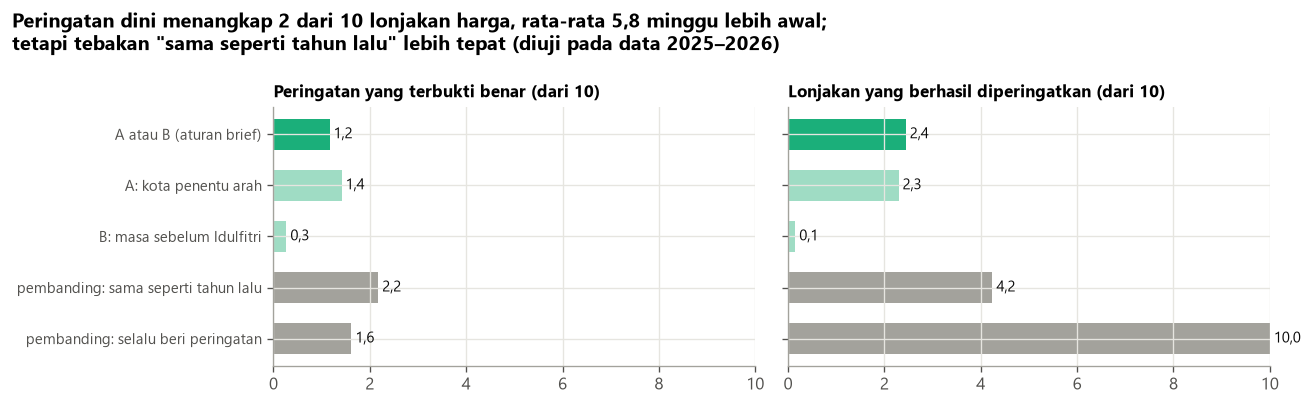

In [4]:
figs = E.figures(ring, bt["detail"])
gambar(figs["skor"])

## 3. Per tahun uji dan per komoditas

In [5]:
per_tahun[["aturan", "tahun_uji", "ketepatan", "tangkapan", "lead_time_rata_minggu"]]

,aturan,tahun_uji,ketepatan,tangkapan,lead_time_rata_minggu
0,A atau B (aturan brief),2025,0.068,0.170,6.119
1,A atau B (aturan brief),2026,0.188,0.326,5.577
2,A: kota penentu arah,2025,0.091,0.141,6.204
3,A: kota penentu arah,2026,0.189,0.326,5.577
4,B: masa sebelum Idulfitri,2025,0.029,0.029,5.700
5,B: masa sebelum Idulfitri,2026,0.000,0.000,NaN
6,pembanding: sama seperti tahun lalu,2025,0.190,0.477,5.651
7,pembanding: sama seperti tahun lalu,2026,0.263,0.367,5.983
8,pembanding: selalu beri peringatan,2025,0.157,1.000,7.624
9,pembanding: selalu beri peringatan,2026,0.168,1.000,6.803


In [6]:
per_kom[per_kom.aturan.isin(["A atau B (aturan brief)", "pembanding: sama seperti tahun lalu",
                             "pembanding: selalu beri peringatan"])].pivot(index="kualitas", columns="aturan",
                                                                           values="ketepatan")

aturan,A atau B (aturan brief),pembanding: sama seperti tahun lalu,pembanding: selalu beri peringatan
kualitas,,,
Bawang Merah Ukuran Sedang,0.070,0.046,0.098
Bawang Putih Ukuran Sedang,0.184,0.193,0.141
Cabai Merah Keriting,0.159,0.268,0.150
Cabai Rawit Merah,0.029,0.160,0.137
Daging Ayam Ras Segar,0.146,0.190,0.295
Telur Ayam Ras Segar,0.011,0.450,0.148


## 4. Contoh: cabai rawit di Jakarta Pusat

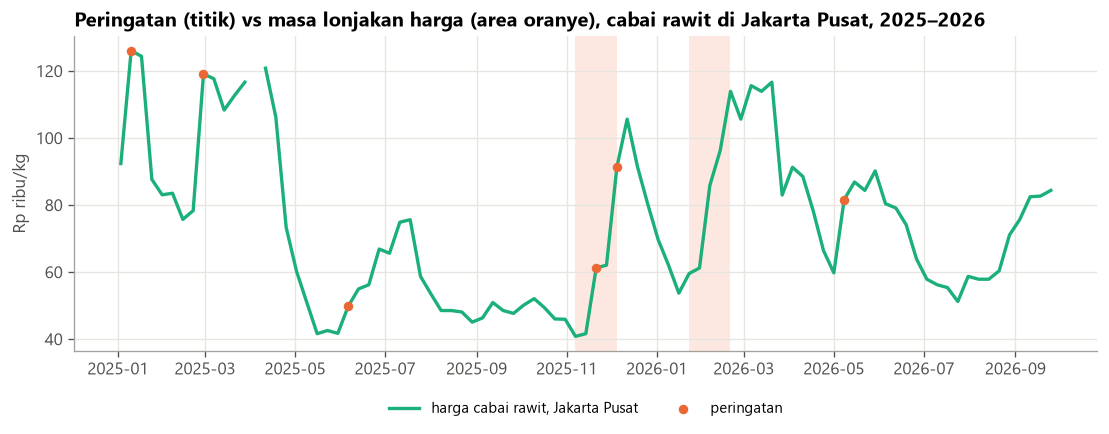

In [7]:
gambar(figs["timeline"])

## 5. Kenapa aturan ini lemah? (interpretasi, bukan bukti)
- Kota penentu arah (Q3) hanya mendahului ±1 minggu dengan hubungan lemah–sedang, dan harga antar kota lebih banyak
  bergerak bersamaan; sinyalnya sering datang bersamaan dengan lonjakan itu sendiri.
- Masa sebelum Idulfitri (Q4) hanya mengulang pola rata-rata, padahal kenaikan menjelang Lebaran sangat berbeda antar tahun.
- Lonjakan cabai kemungkinan banyak dipicu cuaca & panen, yang tidak terlihat dari harga kota lain.
Tebakan "sama seperti tahun lalu" lebih baik, menunjukkan ada pola musiman tahunan yang lebih berguna sebagai pengingat.

## 6. Peringatan terkini (8 minggu terakhir)
Dilatih dengan seluruh data; kolom alasan memakai bahasa dashboard (`reports/tables/q6_peringatan_terkini.csv`).

In [8]:
cur = E.current_alerts(cfg)
cur[cur.peringatan].sort_values("minggu_akhir", ascending=False).head(10)[["minggu_akhir", "kualitas", "kota", "alasan"]]

,minggu_akhir,kualitas,kota,alasan
445,2026-10-09,Cabai Merah Keriting,Kota Kediri,harga cabai merah keriting di Kab. Karanganyar...
493,2026-10-09,Cabai Merah Keriting,Kota Surabaya,harga cabai merah keriting di Kab. Karanganyar...
357,2026-10-09,Cabai Merah Keriting,Kab. Sumenep,harga cabai merah keriting di Kab. Karanganyar...
517,2026-10-09,Cabai Merah Keriting,Kota Tasikmalaya,harga cabai merah keriting di Kab. Karanganyar...
365,2026-10-09,Cabai Merah Keriting,Kab. Tasikmalaya,harga cabai merah keriting di Kab. Karanganyar...
373,2026-10-09,Cabai Merah Keriting,Kab. Wonogiri,harga cabai merah keriting di Kab. Karanganyar...
525,2026-10-09,Cabai Merah Keriting,Kota Tegal,harga cabai merah keriting di Kab. Karanganyar...
381,2026-10-09,Cabai Merah Keriting,Kota Bandung,harga cabai merah keriting di Kab. Karanganyar...
389,2026-10-09,Cabai Merah Keriting,Kota Bekasi,harga cabai merah keriting di Kab. Karanganyar...
349,2026-10-09,Cabai Merah Keriting,Kab. Sukoharjo,harga cabai merah keriting di Kab. Karanganyar...


### Temuan (bahasa dashboard)
Kalimat di bawah **tidak diketik tangan**: diambil dari laporan yang baru saja dibuat skrip, sehingga selalu sama dengan
angka di tabel di atas.

In [9]:
E.write_summary(ring, per_kom, per_tahun, bt["params"], cur, figs, cfg)
tampilkan_temuan("q6_peringatan_dini.md")

**Peringatan dini menangkap 2 dari 10 lonjakan harga, rata-rata 5,8 minggu lebih awal — tetapi belum layak dipakai sebagai pemicu pembelian.**
Peringatan yang terbukti benar: 1,2 dari 10. Ini bahkan lebih rendah daripada memberi peringatan setiap minggu (1,6 dari 10), artinya aturan ini belum lebih baik daripada tebakan acak. Tebakan "sama seperti tahun lalu" justru lebih baik
(2,2 dari 10 benar, menangkap 4,2 dari 10).
Tindakan: jangan pakai aturan ini sebagai pemicu pembelian. Untuk sementara, pakai kalender pola tahun lalu dan pola Idulfitri (mis. bawang merah naik 4 minggu sebelum Lebaran) sebagai pengingat, dan harga di kota penentu arah hanya sebagai informasi tambahan.

Peringatan minggu terakhir (23 Oct 2026): tidak ada peringatan aktif.